# Practical Task 1: Industry Classification from Business-Description Embeddings

In [3]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from sklearn.isotonic import IsotonicRegression
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")

# Loading Data

In [4]:
df = pd.read_pickle("data/df_train.pkl")
df_fin = pd.read_pickle("data/df_financials_train.pkl")
df_train, df_val = train_test_split(df, test_size=0.1, random_state=42)

def embeddings(series):
    # stored as strings "[0.01,-0.02,...]"; json.loads is a fast equivalent of ast.literal_eval
    return np.array([json.loads(s) for s in series], dtype=np.float32)

X_train = embeddings(df_train.business_description_embedding)
X_val = embeddings(df_val.business_description_embedding)
print(X_train.shape, X_val.shape)

#df.head()
#df_fin.head()

(28535, 768) (3171, 768)


# Transforming Data (Label Encoding)

### Tasks:
- Use the scikit-learn label encoder to encode the industry names
- Check if all classes contained in the validation set are also in the training set

In [5]:
le = LabelEncoder().fit(df_train.industry)
y_train = le.transform(df_train.industry)
y_val = le.transform(df_val.industry)
CLASSES, K = le.classes_, len(le.classes_)

print(f"{K} industries; classes in val but not in train: {set(df_val.industry) - set(CLASSES) or 'none'}")

25 industries; classes in val but not in train: none


# Visualize the Data

### Tasks:
- Are certain classes over- or under represented? Either produce a table or a plot to show this.
- Inspect whether there is signal in the business description embeddings:
    - Perform a PCA to project data into 2 dimensions
    - Plot projected data in Scatterplot and color based on classes
    - Provide a description of what you see and judge whether there is signal in the data that allows industry classification

Important: Ensure that your plots have proper axis descriptions and titles. Style the plots so that differences in class distributions are visible (e.g. scatter size, transparency, color, etc.)

### Class distribution

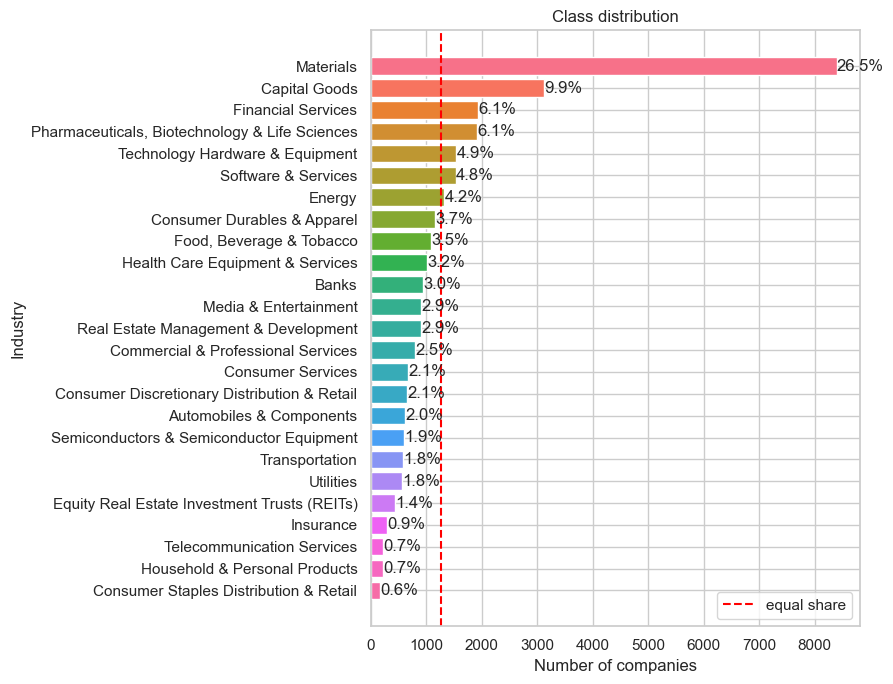

largest / smallest class: 8394 / 178 = 47x


In [6]:

counts = df.industry.value_counts()
palette = dict(zip(counts.index, sns.color_palette("husl", len(counts))))   # one colour per industry, reused below
percentages = counts / counts.sum() * 100


fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(counts.index[::-1], counts.values[::-1], color=[palette[c] for c in counts.index[::-1]])
ax.axvline(counts.mean(), color="red", ls="--", label="equal share")
ax.set(xlabel="Number of companies", ylabel="Industry", title="Class distribution")
for i, (count, percentage) in enumerate(zip(counts.values[::-1], percentages.values[::-1])):
    ax.text(count + 5, i, f"{percentage:.1f}%", va="center")
ax.legend(); 
plt.tight_layout(); 
plt.show()
print(f"largest / smallest class: {counts.max()} / {counts.min()} = {counts.max() / counts.min():.0f}x")


**Findings:** The classes are strongly imbalanced. Materials represent around 25% of all companies, while the
smallest industries (e.g. Consumer Staples Distribution & Retail, Household & Personal Products) are below 1%.

### PCA

removed 4189 shared-embedding + 122 distant points; 24,224 remain


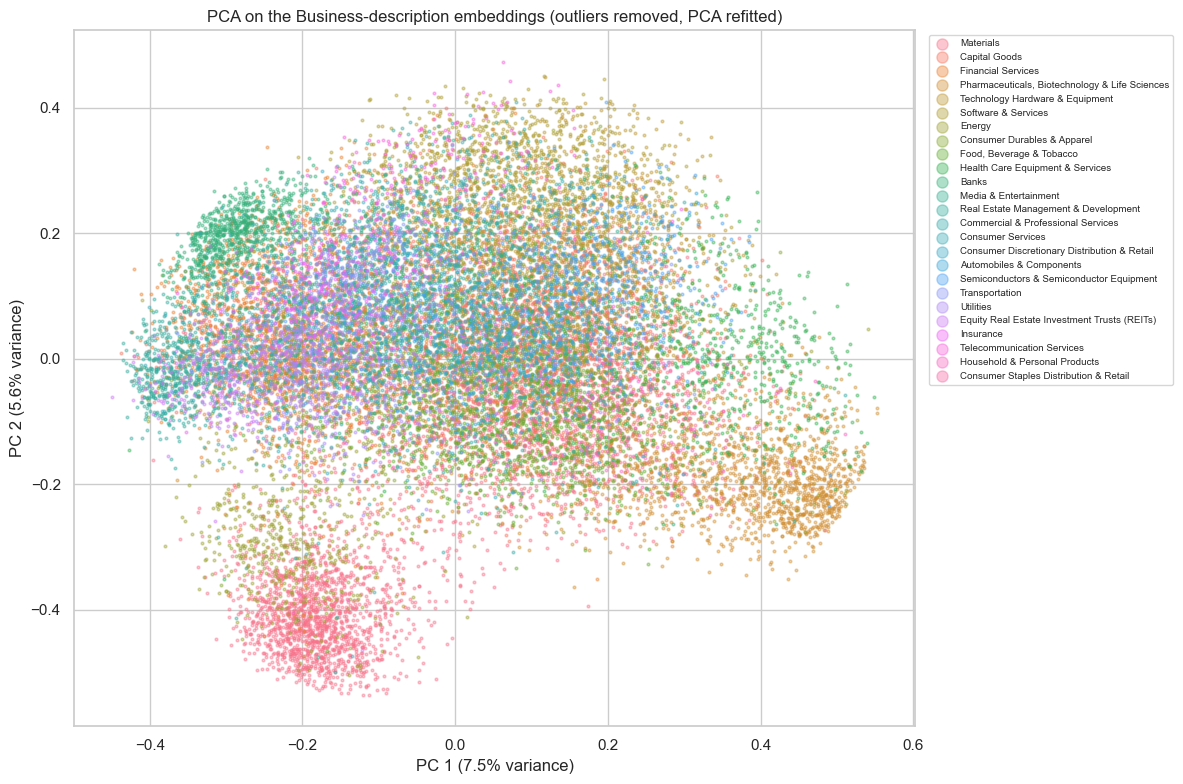

In [7]:
# PCA without outliers
# 1) drop the identical "empty description" embeddings
shared = df_train.business_description_embedding.duplicated(keep=False).values
X_c, ind_c = X_train[~shared], df_train.industry.values[~shared]

# 2) refit PCA on the clean data, then trim points far from the bulk (robust, median-based)
pca_c = PCA(n_components=2).fit(X_c)
Z_c = pca_c.transform(X_c)
dist = np.linalg.norm(Z_c - np.median(Z_c, axis=0), axis=1)
inlier = dist <= np.quantile(dist, 0.995)          # drop the 0.5% most distant points
Z_c, ind_c = Z_c[inlier], ind_c[inlier]
ev_c = 100 * pca_c.explained_variance_ratio_
print(f"removed {shared.sum()} shared-embedding + {(~inlier).sum()} distant points; {len(Z_c):,} remain")

fig, ax = plt.subplots(figsize=(12, 8))
for ind in counts.index:                            # large classes first, small classes on top
    m = ind_c == ind
    ax.scatter(Z_c[m, 0], Z_c[m, 1], s=4, alpha=0.4, color=palette[ind], label=ind)
ax.set(xlabel=f"PC 1 ({ev_c[0]:.1f}% variance)", ylabel=f"PC 2 ({ev_c[1]:.1f}% variance)",
       title="PCA on the Business-description embeddings (outliers removed, PCA refitted)")
ax.legend(markerscale=4, fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

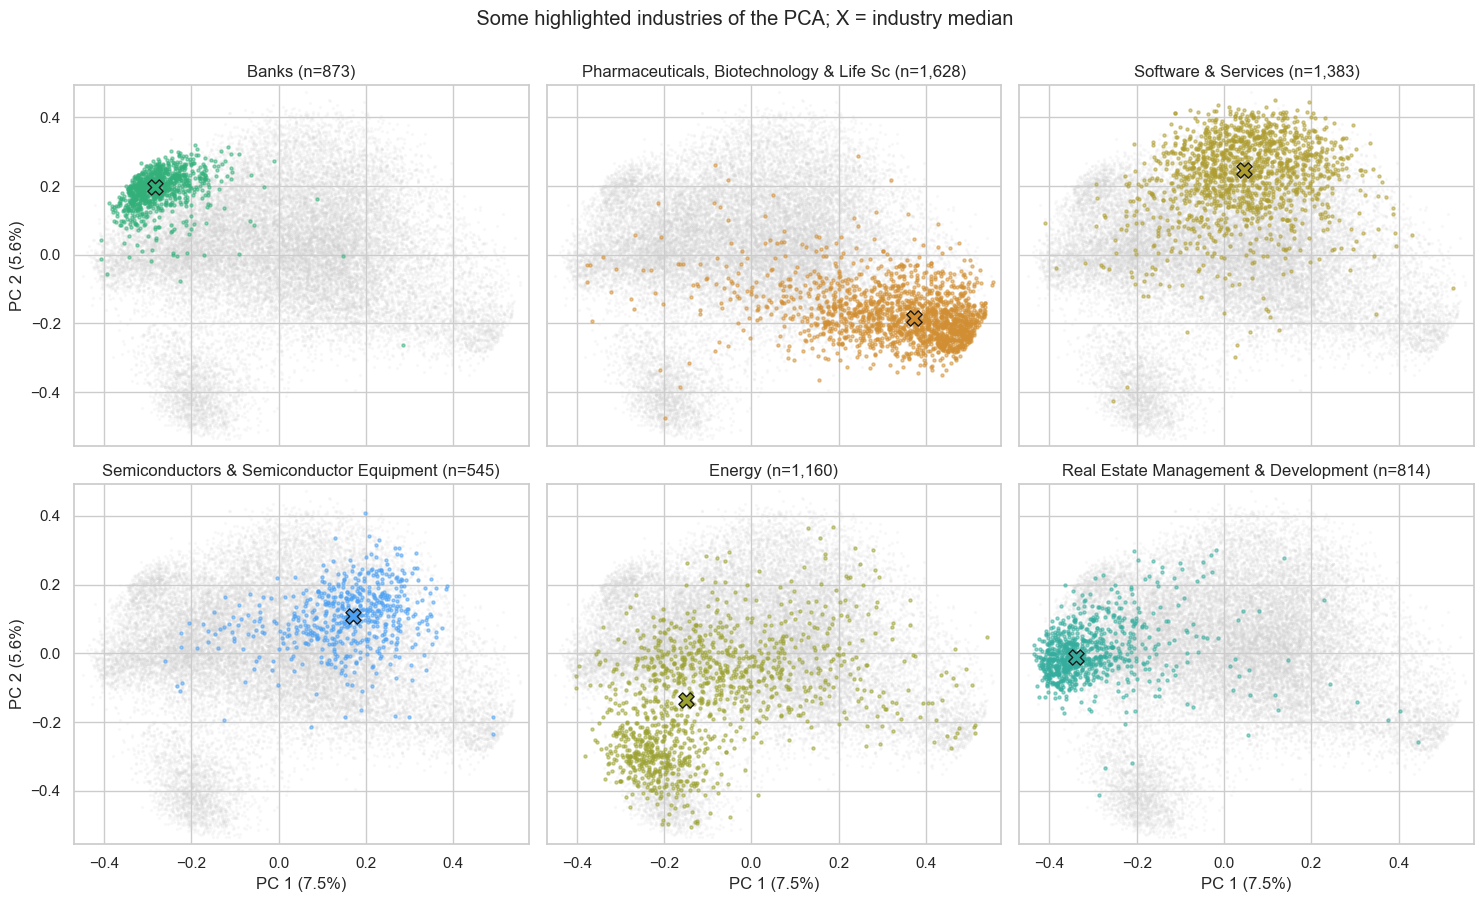

In [8]:
# Highlight a few industries against all others (uses the cleaned PCA from the previous cell)
show = ["Banks",
        "Pharmaceuticals, Biotechnology & Life Sciences",
        "Software & Services",
        "Semiconductors & Semiconductor Equipment",
        "Energy",
        "Real Estate Management & Development"]      # edit this list freely

xlim = (Z_c[:, 0].min() - 0.02, Z_c[:, 0].max() + 0.02)
ylim = (Z_c[:, 1].min() - 0.02, Z_c[:, 1].max() + 0.02)

fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for ax, ind in zip(axes.flat, show):
    m = ind_c == ind
    ax.scatter(Z_c[~m, 0], Z_c[~m, 1], s=2, alpha=0.1, color="lightgrey", rasterized=True)
    ax.scatter(Z_c[m, 0], Z_c[m, 1], s=5, alpha=0.5, color=palette[ind], rasterized=True)
    cx, cy = np.median(Z_c[m], axis=0)               # industry median, to compare across panels
    ax.scatter(cx, cy, marker="X", s=120, color=palette[ind], edgecolor="k", zorder=3)
    ax.set(title=f"{ind[:40]} (n={m.sum():,})", xlim=xlim, ylim=ylim)
for ax in axes[-1]:
    ax.set_xlabel(f"PC 1 ({ev_c[0]:.1f}%)")
for ax in axes[:, 0]:
    ax.set_ylabel(f"PC 2 ({ev_c[1]:.1f}%)")
fig.suptitle(" Some highlighted industries of the PCA; X = industry median", y=1.00)
plt.tight_layout(); plt.show()


**Findings:** The first two components explain only a small part of the variance, we obtain 2-dimensional rough projection of a 768-dimensional space. Still, different industries clearly
occupy different region (e.g. Pharmaceutical and Banking industries sit at opposite ends). Related industries overlap (e.g. Semiconductors and Software). There is clear signal for industry classification, but neighbouring industries will be confused.


# Fitting and Comparing Classifier Models

### Tasks:
- Split the data into train and validation data
- Encode the industry labels using LabelEncoder (scikit-learn)
- Fit a LogisticRegression and a kNN-classifier
- Compare the model performance of both models:
    - Compute Accuracy and F1 score
        - Interpret the scores: Explain how they are computed and judge if your model performs well
        - Analyze the classification errors: 
            - Do the errors correlate with how well classes are represented?
            - Which industries does the model identify well and which seem to be similar?
    - Plot a confusion matrix for both models (combine scikit-learn confusion matrix and seaborn heatmap plot)
    - Do both models misclassify the same examples?

Import: Use proper axis labels for the plots! 

In [9]:

lr = LogisticRegression(C=4, max_iter=2000).fit(X_train, y_train)
knn = KNeighborsClassifier(n_neighbors=15, metric="cosine", weights="distance").fit(X_train, y_train)
pred_lr, pred_knn = lr.predict(X_val), knn.predict(X_val)
baseline = np.full_like(y_val, np.bincount(y_train).argmax())   # always predict the largest class

pd.DataFrame({
    name: {"accuracy": accuracy_score(y_val, p),
           "F1 weighted": f1_score(y_val, p, average="weighted"),
           "F1 macro": f1_score(y_val, p, average="macro")}
    for name, p in [("Majority-class baseline", baseline), ("Logistic Regression", pred_lr), ("kNN (k=15)", pred_knn)]
}).T.round(3)


,accuracy,F1 weighted,F1 macro
Majority-class baseline,0.249,0.099,0.016
Logistic Regression,0.776,0.772,0.706
kNN (k=15),0.775,0.770,0.699



**How the scores are computed**
- **Accuracy** = correctly classified companies / all companies.
- **F1** helps when you have extreme class imbalance in your data and both a false positive and false negative error is similar in cost.:
  - **weighted F1** weights each industry by its size. (**main metric**)
  - **macro F1** gives every industry the same weight, so it shows how well the *small* industries are handled.

Always predicting the largest class gives 25% accuracy and weighted F1 ≈ 0.10

**Do the models perform well?** Yes. Both reach  around 78% accuracy and weighted F1 ≈ 0.77. The remaining errors are mostly
between industries that genuinely overlap . Macro F1 is
lower than weighted F1, which means the small industries are classified worse than the large ones.


### Errors vs. class size

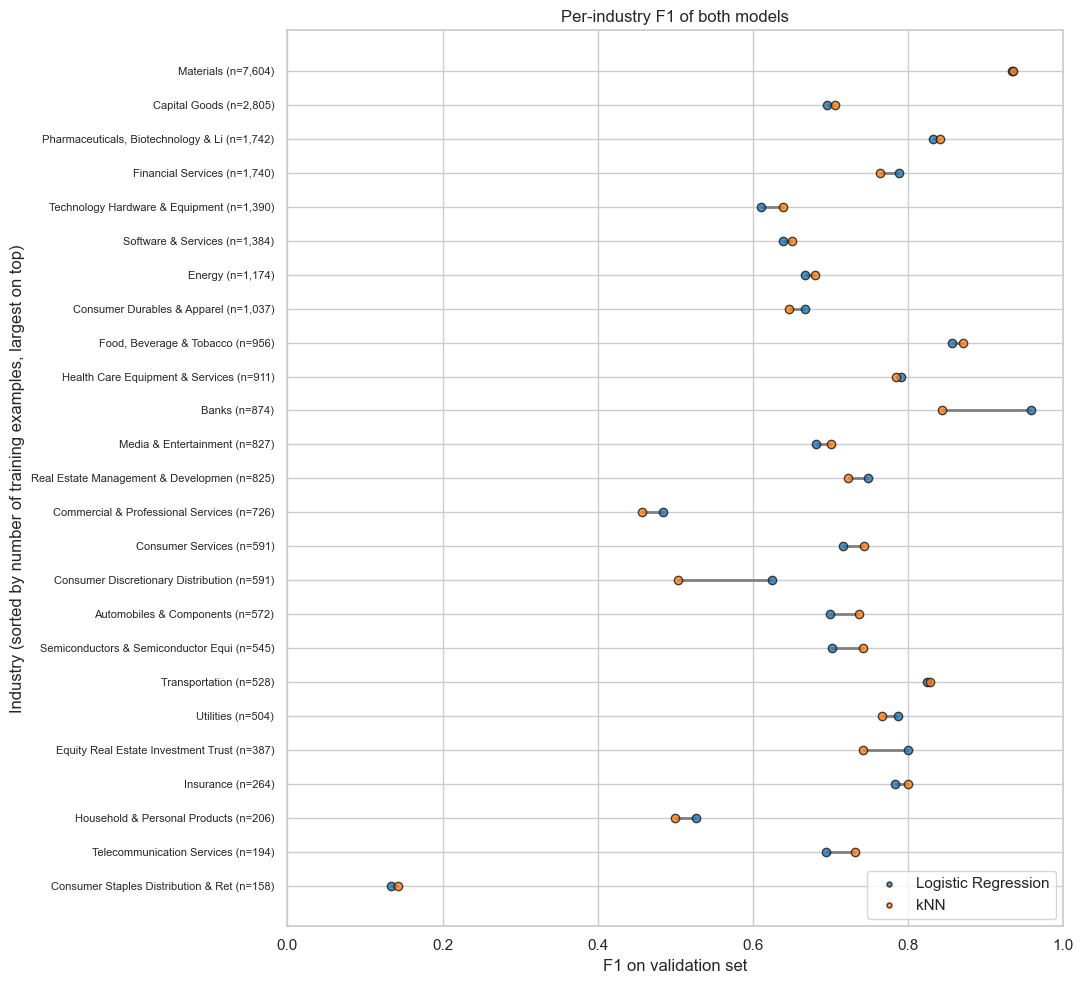

In [29]:

f1_lr = f1_score(y_val, pred_lr, average=None)
f1_knn = f1_score(y_val, pred_knn, average=None)
support = np.bincount(y_train, minlength=K)
order = np.argsort(support)                      # smallest industry at the bottom
ypos = np.arange(K)

fig, ax = plt.subplots(figsize=(11, 10))
ax.hlines(ypos, f1_lr[order], f1_knn[order], color="grey", lw=2, zorder=1)   # gap between the two models
ax.scatter(f1_lr[order], ypos, color="tab:blue", alpha=0.8, edgecolor="k", label="Logistic Regression", zorder=2)
ax.scatter(f1_knn[order], ypos, color="tab:orange", alpha=0.8, edgecolor="k", label="kNN", zorder=2)
ax.set_yticks(ypos, [f"{CLASSES[i][:35]} (n={support[i]:,})" for i in order], fontsize=8)
ax.set(xlabel="F1 on validation set", ylabel="Industry (sorted by number of training examples, largest on top)",
       title="Per-industry F1 of both models",
       xlim=(0, 1))
ax.legend(loc="lower right", markerscale=0.6); plt.tight_layout(); plt.show()

Class representation: Larger classes generally tend to achieve higher F1 scores. For example, Materials, the largest class, has the highest score, while Consumer Staples Distribution & Retail, the smallest class, has the lowest. However, this relationship is not consistent: Telecommunications Services achieves a similar F1 score to Capital Goods despite having approximately 14 times fewer training examples.

Industry identification: The models distinguish several industries well, including Materials, Pharmaceuticals/Biotechnology, Food/Beverage/Tobacco, Banks, and Transportation, which achieve F1 scores above 0.8.

### Which industries are similar?
We measure similarity directly **from the classification errors**: two industries are similar if the model often
confuses them. We turn the confusion rates into a distance and cluster the industries
hierarchically; industries that merge early (short branches) are the ones the model mixes up.

the score in the plot is the relative measure of how often two industries are confused compared with the most-confused pair.

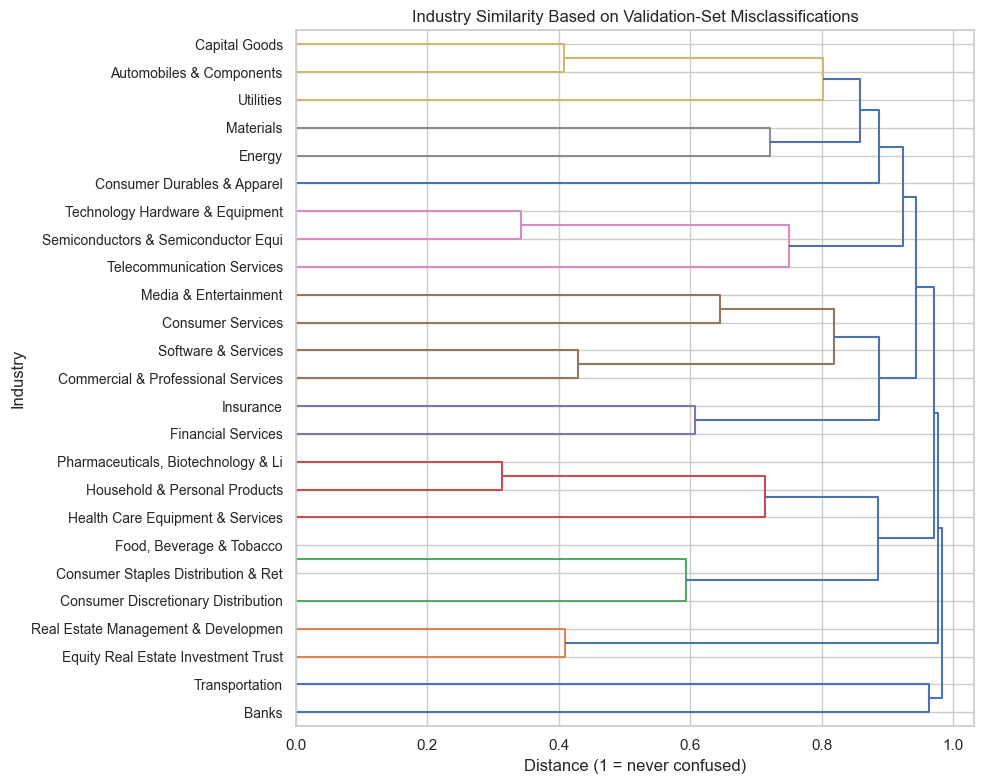

In [27]:
# confusion rate between two industries = share of their companies mistaken for the other (both directions)
rate = confusion_matrix(y_val, pred_lr, normalize="true")
sim = (rate + rate.T) / 2
np.fill_diagonal(sim, 0)
dist = 1 - sim / sim.max()
np.fill_diagonal(dist, 0)

fig, ax = plt.subplots(figsize=(10, 8))
dendrogram(linkage(squareform(dist), method="average"), labels=[c[:35] for c in CLASSES],
           orientation="right", ax=ax, color_threshold=0.85)
ax.set(xlabel="Distance (1 = never confused)", ylabel="Industry",
       title="Industry Similarity Based on Validation-Set Misclassifications")
plt.tight_layout(); plt.show()

Similar industries:

- Capital Goods ↔ Automobiles & Components
- Technology Hardware & Equipment ↔ Semiconductors & Semiconductor Equipment
- Software & Services ↔ Commercial & Professional Services
- Pharmaceuticals & Biotechnology ↔ Household & Personal Products
- Real Estate Management & Development ↔ Equity Real Estate Investment Trusts

These pairs have similar misclassification patterns, suggesting that the model finds them harder to distinguish based on their business descriptions.

### Confusion matrices

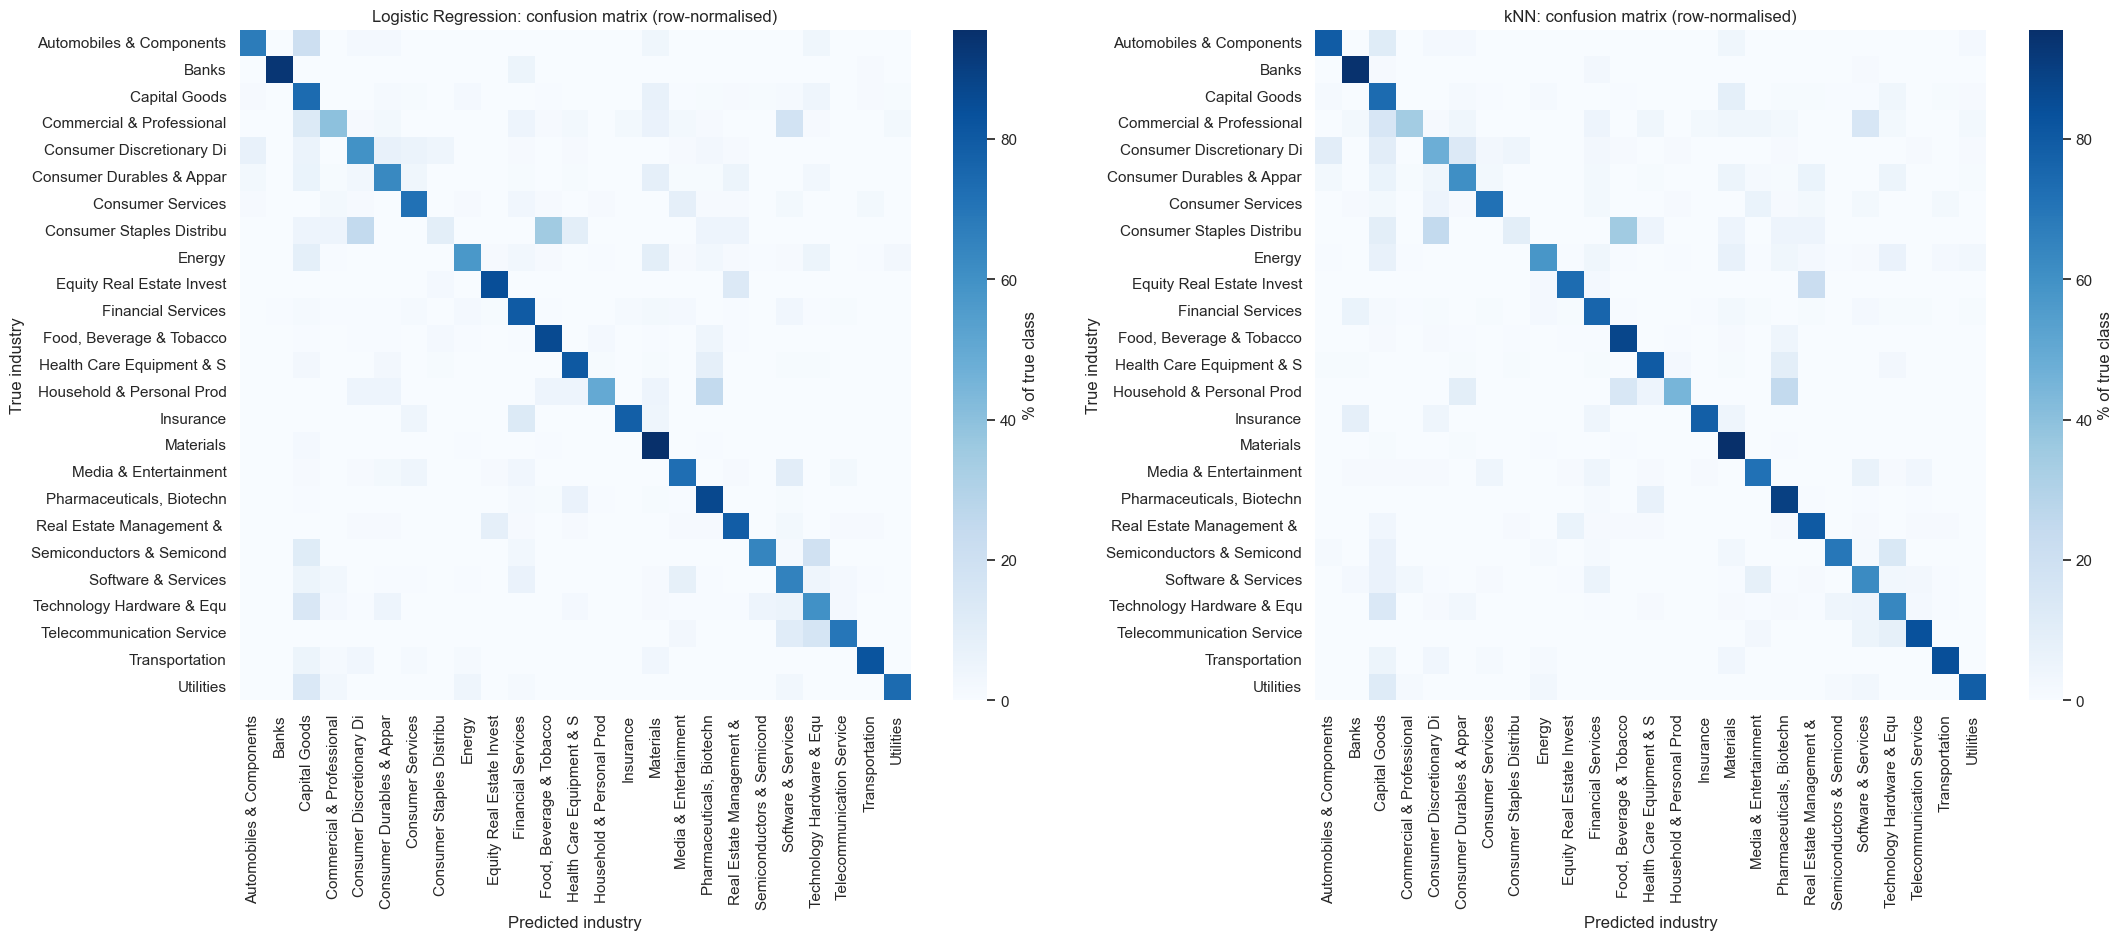

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, (name, p) in zip(axes, [("Logistic Regression", pred_lr), ("kNN", pred_knn)]):
    cm = confusion_matrix(y_val, p, normalize="true")
    sns.heatmap(100 * cm, ax=ax, cmap="Blues", square=True, cbar_kws={"label": "% of true class"},
                xticklabels=[c[:25] for c in CLASSES], yticklabels=[c[:25] for c in CLASSES])
    ax.set(xlabel="Predicted industry", ylabel="True industry", title=f"{name}: confusion matrix (row-normalised)")
plt.tight_layout(); plt.show()

Both models show similar confusion patterns, with most predictions concentrated along the diagonal, indicating correct classifications. However, some off-diagonal errors differ between Logistic Regression and kNN, suggesting that each model also makes some unique mistakes.

### Do both models misclassify the same examples?

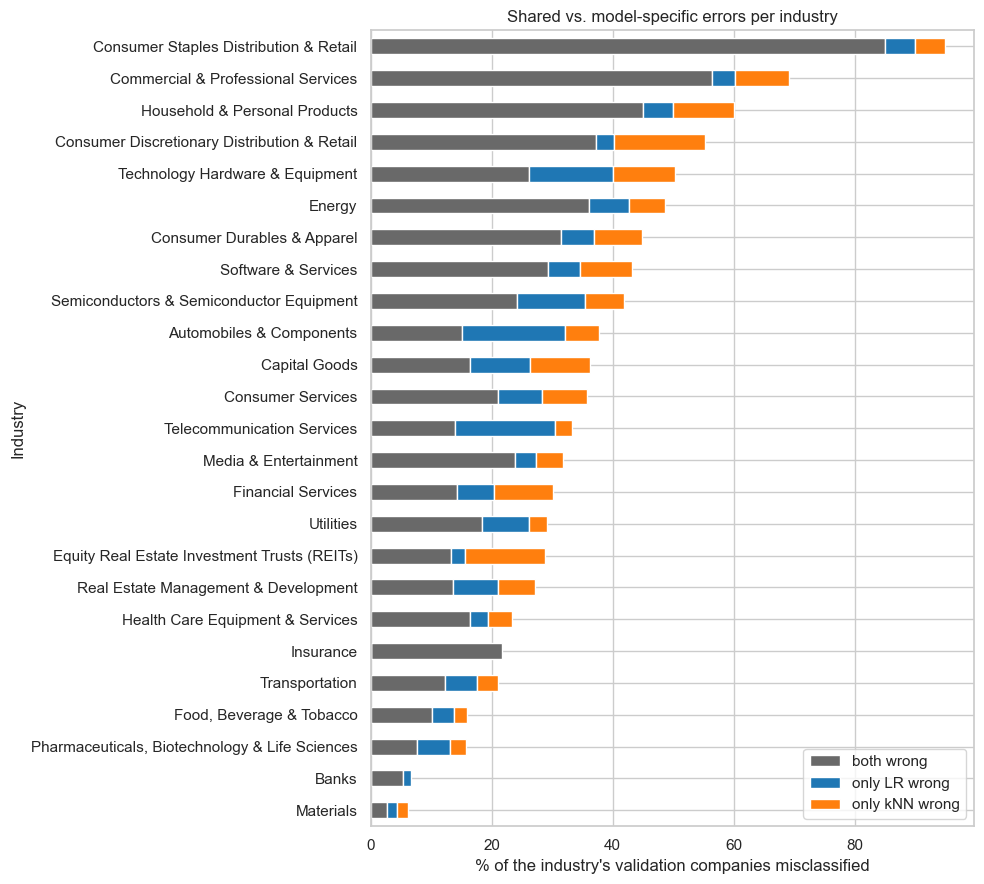

In [15]:
# Per industry: errors made by both models vs. errors made by only one of them (% of the industry's companies)
err = pd.DataFrame({"industry": CLASSES[y_val],
                    "both wrong": ~lr_ok & ~knn_ok,
                    "only LR wrong": ~lr_ok & knn_ok,
                    "only kNN wrong": lr_ok & ~knn_ok}).groupby("industry").mean() * 100
err = err.loc[err.sum(axis=1).sort_values().index]

ax = err.plot.barh(stacked=True, figsize=(10, 9), color=["dimgrey", "tab:blue", "tab:orange"])
ax.set(xlabel="% of the industry's validation set companies misclassified", ylabel="Industry",
       title="Comparison of Models Errors by Industry")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

*Same mistakes?* On the validation set both models mostly fail on the same companies. Neither model is significantly better, but each fixes of
the other, and which model is better depends on the industry (blue vs. orange bars), so combining them helps.


# Optional: Confidence Weighted Prediction

## Deliverables:

- Provide a notebook with the implementation and training of an industry classifier model
- The model shall output the industry classification and its confidence as a tuple of vectors $(\hat{y}_{pred}, \hat{y}_{confidence})$
- The confidence score must be between 0 and 1, $\hat{y}_{confidence} [i] \in [0,1]$
- Your model will be evaluated on a private test set
- Designing the confidence score is your task. You may use p-values, a voting mechanism of multiple models, or other techniques
- Another option is to add more features, e.g. financial data, to X

## Scoring

Your submission is scored with the function `confidence_score` below:

$$\text{score} = F_1^{\text{weighted}}(y, \hat{y}_{pred}) \cdot \left(1 - \text{Brier}\right), \qquad \text{Brier} = \frac{1}{n}\sum_{i=1}^{n} \left(\hat{y}_{confidence}[i] - \mathbb{1}[\hat{y}_{pred}[i] = y_i]\right)^2$$

- **Weighted F1** measures how good your predicted industries are (the confidence does not enter here).
- **Brier score** measures how good your confidence is: $\hat{y}_{confidence}[i]$ should be the probability that prediction $i$ is correct.
- The Brier term is smallest when your confidence is *calibrated*: among all predictions with confidence 0.8, about 80% should be correct.
- Always reporting confidence 1.0 does not pay off (every wrong prediction costs the maximum penalty), and neither does reporting very low confidence everywhere.

In [16]:
def confidence_score(y_true, y_pred, confidence):
    y_true, y_pred, confidence = np.asarray(y_true), np.asarray(y_pred), np.asarray(confidence, dtype=float)
    assert np.all((confidence >= 0) & (confidence <= 1))
    f1 = f1_score(y_true, y_pred, average="weighted")
    brier = np.mean((confidence - (y_true == y_pred)) ** 2)
    return f1 * (1 - brier)

print(f"baseline (LR, max probability): {confidence_score(y_val, pred_lr, lr.predict_proba(X_val).max(1)):.4f}")


baseline (LR, max probability): 0.6658


### Financial data: outliers, missing values and distributions across industries
- Ratios with a zero denominator are ±∞ → set to NaN, but keep a flag (zero revenue is informative,
  e.g. exploration miners, pre-revenue biotechs).
- Extreme outliers → winsorise at the 1% / 99% quantiles.
- Missing values (EBITDA margin is missing for ~65%) → kept as NaN, which gradient boosting handles natively.
- Some ids have two rows (one empty) → take the first non-missing value per id.

In [17]:
FIN = ["net_profit_margin", "ebitda_margin", "asset_turnover"]

def clean_financials(fin, clip=None):
    g = fin.copy()
    for c in FIN:
        g[c + "_inf"] = np.sign(g[c]).where(np.isinf(g[c]), 0)   # +1 / -1 / 0
        g[c] = g[c].replace([np.inf, -np.inf], np.nan)
    g = g.groupby("id").first()
    clip = clip or {c: g[c].quantile([0.01, 0.99]).tolist() for c in FIN}
    for c in FIN:
        g[c] = g[c].clip(*clip[c])
    return g, clip

fin_clean, _ = clean_financials(df_fin)
dfm = df[["id", "industry"]].join(fin_clean, on="id", how="inner")
print(f"{len(dfm):,} of {len(df):,} companies have financial data")

29,400 of 31,706 companies have financial data


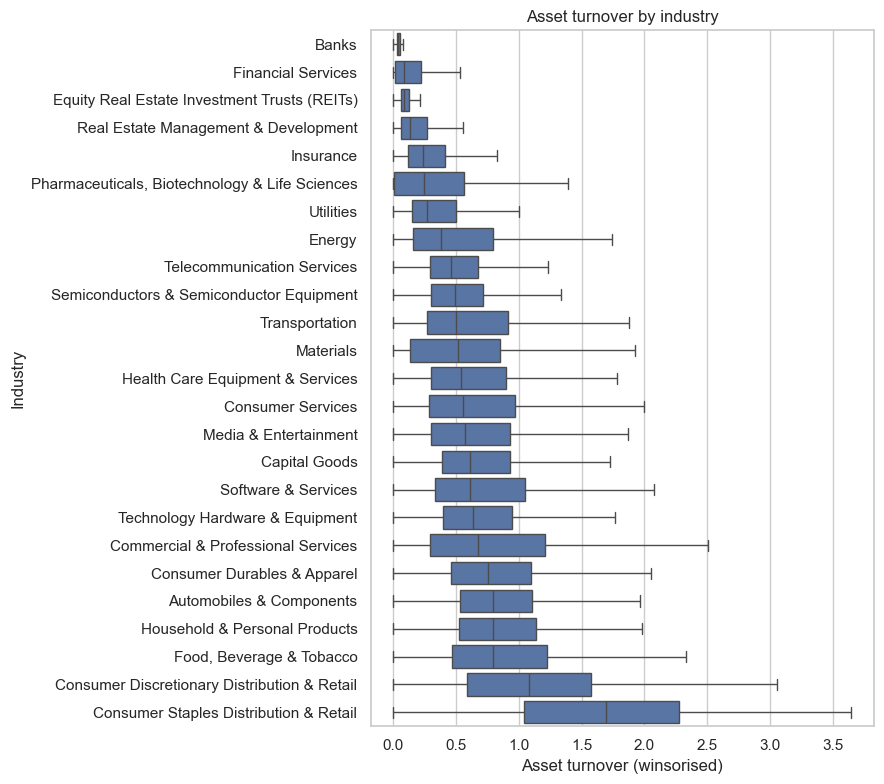

net_profit_margin  H =    2896   p = 0.0e+00
ebitda_margin      H =    1818   p = 0.0e+00
asset_turnover     H =    6096   p = 0.0e+00


In [18]:
fig, ax = plt.subplots(figsize=(9, 8))
order = dfm.groupby("industry").asset_turnover.median().sort_values().index
sns.boxplot(data=dfm, y="industry", x="asset_turnover", order=order, showfliers=False, ax=ax)
ax.set(xlabel="Asset turnover (winsorised)", ylabel="Industry", title="Asset turnover by industry")
plt.tight_layout(); plt.show()

# Kruskal-Wallis: H0 = the ratio has the same distribution in all industries (rank-based, robust to outliers)
for c in FIN:
    H, p = stats.kruskal(*[g.dropna() for _, g in dfm.groupby("industry")[c]])
    print(f"{c:18s} H = {H:7.0f}   p = {p:.1e}")

**Findings:** All three ratios differ significantly between industries (p ≈ 0), and the differences make economic
sense (banks and REITs have very low asset turnover, retailers very high; biotechs have negative margins).
But the distributions overlap heavily, so financial data is only a weak, complementary signal.


### Ensemble with calibrated confidence and p-values
1. **Embedding models:** weighted average of Logistic Regression and kNN probabilities (weight $w$).
2. **Financial model:** gradient boosting on the cleaned ratios + country. It is weak, so it only *corrects* the
   embedding prediction: $\log P = \log P_{emb} + \alpha(\log P_{fin} - \log P_{prior})$.
3. **Confidence:** the maximum ensemble probability, calibrated with isotonic regression on out-of-fold predictions.
4. **p-values (conformal prediction):** for industry $k$, $p_k$ = share of training companies whose true-class
   probability was as low as or lower than $P(k \mid x)$. Industries with $p_k > 0.1$ form a 90% prediction set.
   A prediction is **flagged for human review** if this set contains more than one industry or the confidence is below 0.5.

**Avoiding overfitting.** Every choice ($w$, $\alpha$, the calibrator) is made on **out-of-fold** predictions
from 5-fold cross-validation *inside the training data*: each training company is predicted by models that never
saw it. The validation set is used only once, for the final evaluation. The search grid is deliberately small
(4 × 3 values), and the calibrator is isotonic regression on a single number, so there is little to overfit.


In [19]:
W_GRID, ALPHA_GRID = [0.4, 0.5, 0.6, 0.7], [0, 0.25, 0.5]

def fin_features(ids, fin_clean, countries):
    F = fin_clean.reindex(ids)
    has_fin = F.drop(columns="country_code").notna().any(axis=1).to_numpy()
    country = pd.Categorical(F.pop("country_code"), categories=countries).codes.astype(float)
    F["country"] = np.where(country < 0, np.nan, country)   # last column, treated as categorical
    return F.to_numpy(float), has_fin

def expand(P, classes):
    """put probabilities of the classes seen by a model into a full K-column matrix"""
    out = np.full((len(P), K), 1e-6)
    out[:, classes] = P
    return out / out.sum(1, keepdims=True)

def combine(P_lr, P_knn, P_fin, prior, w, alpha):
    L = np.log(w * P_lr + (1 - w) * P_knn + 1e-6) + alpha * (np.log(P_fin + 1e-6) - np.log(prior))
    P = np.exp(L - L.max(1, keepdims=True))
    return P / P.sum(1, keepdims=True)

def fit_models(X, y, F, has_fin):
    fin_model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                               categorical_features=[F.shape[1] - 1], random_state=0)
    return {"lr": LogisticRegression(C=4, max_iter=2000).fit(X, y),
            "knn": KNeighborsClassifier(15, metric="cosine", weights="distance").fit(X, y),
            "fin": fin_model.fit(F[has_fin], y[has_fin])}

def base_proba(models, X, F, has_fin, prior):
    """probabilities of the three experts: LR, kNN, financial (= prior if no financial data)"""
    P_fin = np.tile(prior, (len(X), 1))
    if has_fin.any():
        P_fin[has_fin] = expand(models["fin"].predict_proba(F[has_fin]), models["fin"].classes_)
    return (expand(models["lr"].predict_proba(X), models["lr"].classes_),
            expand(models["knn"].predict_proba(X), models["knn"].classes_), P_fin)

def fit_ensemble(df, df_fin):
    X = embeddings(df.business_description_embedding)
    y = le.transform(df.industry)
    fin_clean, clip = clean_financials(df_fin)
    countries = sorted(fin_clean.country_code.dropna().unique())
    F, has_fin = fin_features(df.id.values, fin_clean, countries)
    prior = np.bincount(y, minlength=K) / len(y)

    # out-of-fold predictions: every training company is predicted by models that did not see it
    P_lr, P_knn, P_fin = (np.zeros((len(y), K)) for _ in range(3))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(X, y):
        P_lr[te], P_knn[te], P_fin[te] = base_proba(fit_models(X[tr], y[tr], F[tr], has_fin[tr]),
                                                    X[te], F[te], has_fin[te], prior)

    # choose the ensemble weights on the out-of-fold predictions only (no validation data involved)
    def oof_score(w, alpha):
        P = combine(P_lr, P_knn, P_fin, prior, w, alpha)
        return confidence_score(y, P.argmax(1), P.max(1))
    grid = pd.Series({(w, a): oof_score(w, a) for w in W_GRID for a in ALPHA_GRID})
    w, alpha = grid.idxmax()

    P_oof = combine(P_lr, P_knn, P_fin, prior, w, alpha)
    correct = (P_oof.argmax(1) == y).astype(float)
    return {"models": fit_models(X, y, F, has_fin), "clip": clip, "countries": countries, "prior": prior,
            "w": w, "alpha": alpha, "grid": grid,
            "oof": {"P": P_oof, "y": y, "P_lr": P_lr, "P_knn": P_knn, "has_fin": has_fin},
            "calibrator": IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(P_oof.max(1), correct),
            "scores": np.sort(1 - P_oof[np.arange(len(y)), y])}

def predict(model, df, df_fin):
    """returns (y_pred, y_confidence, p_values)"""
    X = embeddings(df.business_description_embedding)
    F, has_fin = fin_features(df.id.values, clean_financials(df_fin, model["clip"])[0], model["countries"])
    P = combine(*base_proba(model["models"], X, F, has_fin, model["prior"]), model["prior"], model["w"], model["alpha"])
    s = model["scores"]
    p_values = (1 + len(s) - np.searchsorted(s, 1 - P)) / (len(s) + 1)
    return le.inverse_transform(P.argmax(1)), model["calibrator"].predict(P.max(1)), p_values

**How could the model be improved?** What we tried:

| Change | Effect on accuracy |
|---|---|
| LR alone / kNN alone | 77.7% / 77.6% |
| Tune LR (`C` 0.5–8) and kNN (k 5–30) | best at C = 4, k = 15; differences < 1 pp |
| Other single models: MLP (1 hidden layer), RBF-SVM | 76–78%, no gain, much slower |
| Average LR + kNN probabilities | **+1.5 pp** (≈79%) – the largest gain |
| Stack LR + kNN + financial data with gradient boosting | ≈78.4%, worse than simple averaging |
| Add financial/country correction | ≈ ±0.2 pp accuracy, but better confidence (lower Brier) |
| Isotonic calibration of the confidence | Brier ↓, score ↑ (accuracy unchanged) |
| Larger grid (C, k, w, α: 144 settings) chosen on out-of-fold data | +0.001 score – smaller than the noise (see bootstrap CI), not kept |
| Gradient-boosted meta-calibrator for the confidence | +0.0006 score – not worth the extra complexity |

All models level off at 77–79%, which points to a limit in the data (overlapping industries, ~14% of
companies without a description) rather than in the model. Remaining ideas: use the raw description text or a
stronger embedding model, weight the small classes more (helps macro F1, may cost weighted F1), and add a third,
different model to the vote.

In [20]:

t0 = time.time()
model = fit_ensemble(df_train, df_fin)
print(f"training time: {time.time() - t0:.0f}s")
print(f"weights chosen on out-of-fold data: w = {model['w']}, alpha = {model['alpha']}")
display(model["grid"].unstack().rename_axis(index="w (LR weight)", columns="alpha (financial)"))

y_pred, conf, p_values = predict(model, df_val, df_fin)
y_true = df_val.industry.values
correct = y_pred == y_true
print(f"validation: accuracy {correct.mean():.4f} | F1 weighted {f1_score(y_true, y_pred, average='weighted'):.4f} | "
      f"Brier {np.mean((conf - correct) ** 2):.4f} | score {confidence_score(y_true, y_pred, conf):.4f}")


training time: 95s
weights chosen on out-of-fold data: w = 0.6, alpha = 0.25


alpha (financial),0.00,0.25,0.50
w (LR weight),,,
0.4,0.677486,0.683304,0.682367
0.5,0.678580,0.684722,0.683054
0.6,0.679118,0.685491,0.683295
0.7,0.678491,0.684130,0.681697


validation: accuracy 0.7878 | F1 weighted 0.7839 | Brier 0.1295 | score 0.6824


### Can the confidence be improved further?
We compare confidence functions, again only on the out-of-fold training predictions (each calibrator is itself
cross-validated, so it is always scored on companies it was not fitted on):
- **raw**: the maximum ensemble probability,
- **isotonic**: the monotone mapping of that probability to the observed accuracy (used in the model),
- **logistic meta-calibrator**: a logistic regression that predicts "is this prediction correct?" from several
  signals – max probability, gap to the runner-up, whether LR and kNN agree, and whether financial data exists.

In [21]:
o = model["oof"]
P_sorted = np.sort(o["P"], 1)
pred_oof = o["P"].argmax(1)
ok_oof = (pred_oof == o["y"]).astype(float)
signals = np.c_[np.log(P_sorted[:, -1] / (1 - P_sorted[:, -1] + 1e-6)),     # logit of max probability
                P_sorted[:, -1] - P_sorted[:, -2],                              # gap to runner-up
                o["P_lr"].argmax(1) == pred_oof, o["P_knn"].argmax(1) == pred_oof,  # model agreement
                o["has_fin"]]

conf_cv = {"raw": o["P"].max(1), "isotonic": np.zeros(len(ok_oof)), "logistic meta-calibrator": np.zeros(len(ok_oof))}
for a, b in StratifiedKFold(5, shuffle=True, random_state=1).split(signals, ok_oof):
    conf_cv["isotonic"][b] = IsotonicRegression(out_of_bounds="clip").fit(o["P"].max(1)[a], ok_oof[a]).predict(o["P"].max(1)[b])
    conf_cv["logistic meta-calibrator"][b] = LogisticRegression(max_iter=1000).fit(signals[a], ok_oof[a]).predict_proba(signals[b])[:, 1]

pd.DataFrame({name: {"Brier": np.mean((c - ok_oof) ** 2), "score": confidence_score(o["y"], pred_oof, c)}
              for name, c in conf_cv.items()}).T.round(4)

,Brier,score
raw,0.1282,0.6855
isotonic,0.1276,0.6860
logistic meta-calibrator,0.1271,0.6864


### How certain is the validation score? (bootstrap confidence interval)
The validation set has only 3,171 companies, so the score itself is uncertain. We resample the validation set
1,000 times with replacement and recompute the score, giving a 95% confidence interval. A *paired* bootstrap
(same resamples for both models) tests whether the ensemble is really better than the plain LR baseline.

In [22]:
rng = np.random.default_rng(0)
conf_lr = lr.predict_proba(X_val).max(1)
pred_ens = le.transform(y_pred)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(y_val), len(y_val))
    boot.append((confidence_score(y_val[i], pred_ens[i], conf[i]), confidence_score(y_val[i], pred_lr[i], conf_lr[i])))
boot = np.array(boot)

for name, s in [("ensemble", boot[:, 0]), ("LR baseline", boot[:, 1]), ("difference", boot[:, 0] - boot[:, 1])]:
    lo, hi = np.percentile(s, [2.5, 97.5])
    print(f"{name:12s} 95% CI [{lo:.4f}, {hi:.4f}]")
print(f"share of resamples where the ensemble is better: {np.mean(boot[:, 0] > boot[:, 1]):.1%}")

ensemble     95% CI [0.6657, 0.6976]
LR baseline  95% CI [0.6485, 0.6819]
difference   95% CI [0.0100, 0.0236]
share of resamples where the ensemble is better: 100.0%


**Findings – confidence:**
- The weight search on out-of-fold data picks w = 0.6, α = 0.25. All 12 settings score between 0.677 and
  0.685, so the result is not sensitive to the exact choice. α = 0 (no financial data) is the worst in every row,
  so the financial correction does help the confidence score.
- The isotonic confidence is already close to the best we can get: a logistic meta-calibrator that also uses the
  runner-up gap and model agreement lowers the Brier score only from 0.1273 to 0.1268 (+0.0004 score). That is
  far below the uncertainty of the score (bootstrap above), so we keep the simpler isotonic calibration.
- No sign of overfitting: the out-of-fold score on the training data (≈ 0.686) and the validation score
  (≈ 0.683) are almost the same.
- The ensemble is clearly better than the plain LR baseline: the paired bootstrap difference is +0.009 to +0.023
  (95% CI) and positive in every resample.
- Why the confidence cannot get much better: the Brier score of a well-calibrated model is roughly
  $E[c(1-c)]$, which is large whenever ~20% of predictions are wrong. To reduce it substantially the
  *accuracy* would have to improve, not the calibration.

### Confidence vs. accuracy and human review

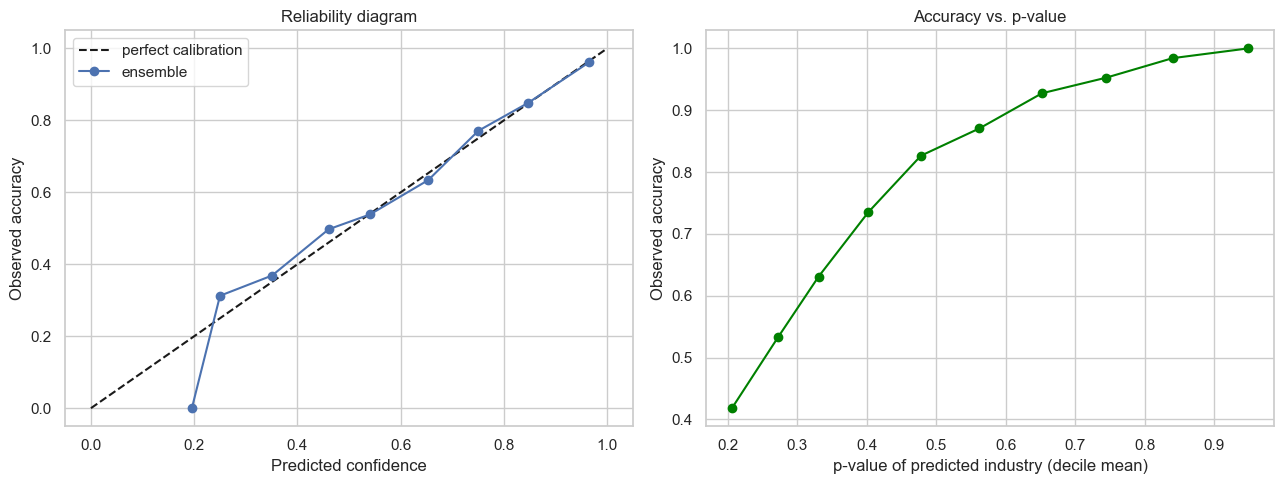

90% prediction sets: coverage 0.902, mean size 1.54


,share,accuracy
automatic,0.588,0.928
flagged for review,0.412,0.588


In [23]:
set_size = (p_values > 0.1).sum(1)
review = (set_size > 1) | (conf < 0.5)
p_pred = p_values.max(1)   # p-value of the predicted industry

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bins = pd.cut(conf, np.linspace(0, 1, 11))
rel = pd.DataFrame({"conf": conf, "ok": correct}).groupby(bins, observed=True).mean()
axes[0].plot([0, 1], [0, 1], "k--", label="perfect calibration")
axes[0].plot(rel.conf, rel.ok, "o-", label="ensemble")
axes[0].set(xlabel="Predicted confidence", ylabel="Observed accuracy", title="Reliability diagram")
axes[0].legend()

dec = pd.DataFrame({"p": p_pred, "ok": correct}).groupby(pd.qcut(p_pred, 10, duplicates="drop"), observed=True).mean()
axes[1].plot(dec.p, dec.ok, "o-", color="green")
axes[1].set(xlabel="p-value of predicted industry (decile mean)", ylabel="Observed accuracy",
            title="Accuracy vs. p-value")
plt.tight_layout(); plt.show()

print(f"90% prediction sets: coverage {np.mean(p_values[np.arange(len(y_true)), le.transform(y_true)] > 0.1):.3f}, "
      f"mean size {set_size.mean():.2f}")
pd.DataFrame({"share": [1 - review.mean(), review.mean()],
              "accuracy": [correct[~review].mean(), correct[review].mean()]},
             index=["automatic", "flagged for review"]).round(3)

**Findings:**
- Combining LR and kNN raises accuracy from ~77.7% to ~79%. The financial correction barely changes accuracy but
  improves the confidence estimates (lower Brier score). The final validation score is ≈ 0.683 (95% CI 0.666–0.698; LR baseline 0.667), a significant improvement.
- The confidence is well calibrated (reliability curve close to the diagonal), and the p-value of the predicted
  industry is strongly related to correctness.
- About 59% of companies are classified automatically with ~93% accuracy; the other ~41% are flagged for review.
- The 85% target is not reached: with this score, 0.85 would need ~92% accuracy, while all models we tried
  (LR, kNN, MLP, SVM) plateau at 77–79%.

### Final model (trained on all data) for the private test set

In [24]:
t0 = time.time()
final_model = fit_ensemble(df, df_fin)
print(f"training time on all {len(df):,} companies: {time.time() - t0:.0f}s")

# df_test, df_fin_test = pd.read_pickle(...), pd.read_pickle(...)
# y_pred, y_confidence, _ = predict(final_model, df_test, df_fin_test)

training time on all 31,706 companies: 137s
